#  Interactive Magic Sketchbook — Hand-Drawn Animation
**Computer Vision Project**

**Pipeline:**
`Image → Preprocess → Sketch → Contours → Segmentation → Parts → Masks → Extraction → Joints → Rig → Animation (GIF)`

| # | Section |
|---|---|
| 01 | Project Setup |
| 02 | Data Acquisition |
| 03 | Data Exploration |
| 04 | Image Preprocessing |
| 05 | Sketch Extraction |
| 06 | Contour Detection |
| 07 | Image Segmentation |
| 08 | Part Detection |
| 09 | Mask Generation |
| 10 | Part Extraction |
| 11 | Joint Detection |
| 12 | Character Structuring |
| 13 | Output Generation |
| 14 | Pipeline Testing |
| 15 | Pipeline Export |

## 01. Project Setup


In [1]:
import os, time, inspect
import cv2
import numpy as np
import matplotlib.pyplot as plt
from dataclasses import dataclass
from typing import Optional, Tuple
from PIL import Image as PILImage

try:
    from IPython.display import Image as IPyImage, display
except ImportError:          # running outside Jupyter
    IPyImage, display = None, print

print("OpenCV :", cv2.__version__)
print("NumPy  :", np.__version__)

OUT_DIR = "outputs"
os.makedirs(OUT_DIR, exist_ok=True)

# ---- global constants used by the rig / renderer ----
SKIN  = (255, 213, 170)
DARK  = (60, 40, 30)
COLORS = {                        # stroke colour for each body part (RGB)
    "torso": (70, 110, 230),
    "arm_l": (230, 90, 90),
    "arm_r": (230, 90, 90),
    "leg_l": (60, 170, 120),
    "leg_r": (60, 170, 120),
}
PARENT  = {"torso": None, "head": "torso", "arm_l": "torso", "arm_r": "torso",
           "leg_l": "torso", "leg_r": "torso"}          # skeleton hierarchy
Z_ORDER = {"leg_l": 0, "leg_r": 0, "torso": 1, "arm_l": 2, "arm_r": 2, "head": 3}

def show(images, titles=None, cols=3, size=(5, 4.5)):
    # display a list of images (RGB or gray) in a grid
    n = len(images); rows = (n + cols - 1) // cols
    plt.figure(figsize=(size[0] * min(n, cols), size[1] * rows))
    for i, im in enumerate(images):
        plt.subplot(rows, cols, i + 1)
        if im.ndim == 2:
            plt.imshow(im, cmap="gray")
        else:
            plt.imshow(im)
        if titles: plt.title(titles[i])
        plt.axis("off")
    plt.tight_layout(); plt.show()

OpenCV : 5.0.0
NumPy  : 2.5.4


## 02. Data Acquisition


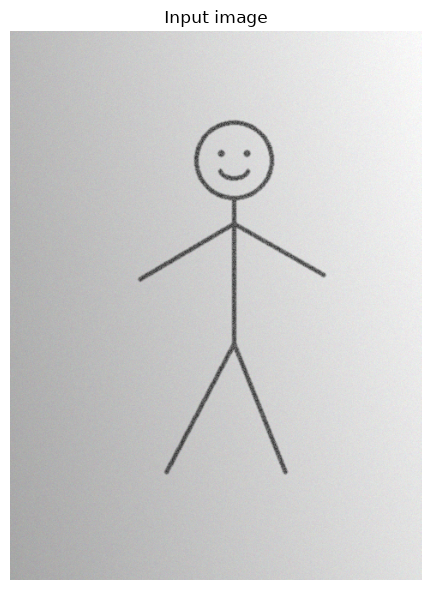

In [2]:
IMAGE_PATH = None      # e.g. "my_drawing.jpg"  (None -> use synthetic drawing)

def generate_synthetic_drawing(seed=0, size=(640, 480), noise=4.0, rotate=0.0):
    # fake "photo" of a pencil stick-figure drawn on paper (RGB uint8)
    rng = np.random.default_rng(seed)
    H, W = size
    cx = W // 2 + int(rng.integers(-30, 30))
    head_r = int(rng.integers(38, 48)); head_c = (cx, 150)
    neck = (cx, head_c[1] + head_r)
    sh = (cx, neck[1] + 30)
    hip = (cx, neck[1] + 170)
    j = lambda a: int(rng.integers(-a, a + 1))

    canvas = np.zeros((H, W), np.uint8)
    cv2.circle(canvas, head_c, head_r, 255, 4)                       # head
    cv2.circle(canvas, (cx - 15, head_c[1] - 8), 4, 255, -1)         # eyes
    cv2.circle(canvas, (cx + 15, head_c[1] - 8), 4, 255, -1)
    cv2.ellipse(canvas, (cx, head_c[1] + 12), (16, 9), 0, 0, 180, 255, 3)   # smile
    cv2.line(canvas, neck, hip, 255, 4)                              # body
    cv2.line(canvas, sh, (cx - 110 + j(12), sh[1] + 70 + j(10)), 255, 4)    # arms
    cv2.line(canvas, sh, (cx + 110 + j(12), sh[1] + 70 + j(10)), 255, 4)
    cv2.line(canvas, hip, (cx - 70 + j(10), hip[1] + 150), 255, 4)          # legs
    cv2.line(canvas, hip, (cx + 70 + j(10), hip[1] + 150), 255, 4)

    canvas = cv2.GaussianBlur(canvas, (3, 3), 0)
    pencil = (canvas / 255.0) * rng.uniform(0.6, 1.0, canvas.shape)  # uneven pencil pressure

    gx = np.linspace(0.78, 1.05, W)[None, :, None]                   # uneven lighting
    gy = np.linspace(1.00, 0.90, H)[:, None, None]
    paper = np.full((H, W, 3), 238.0) * gx * gy
    paper += rng.normal(0, noise, paper.shape)                       # sensor noise
    paper *= (1 - 0.75 * pencil)[..., None]
    img = np.clip(paper, 0, 255).astype(np.uint8)

    if rotate:                                                       # camera tilt
        M = cv2.getRotationMatrix2D((W / 2, H / 2), rotate, 1.0)
        img = cv2.warpAffine(img, M, (W, H), borderValue=(220, 220, 220))
    return img

def load_image(path=None, **kw):
    if path is None:
        return generate_synthetic_drawing(**kw)
    bgr = cv2.imread(path)
    if bgr is None:
        raise FileNotFoundError(path)
    img = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)
    scale = 640 / max(img.shape[:2])             # keep the working size reasonable
    return cv2.resize(img, None, fx=scale, fy=scale) if scale < 1 else img

img = load_image(IMAGE_PATH)
show([img], ["Input image"], cols=1, size=(5, 6))

## 03. Data Exploration


shape : (640, 480, 3) | dtype: uint8
range : 48 -> 255
mean per channel (R,G,B): [204.2 204.2 204.2]


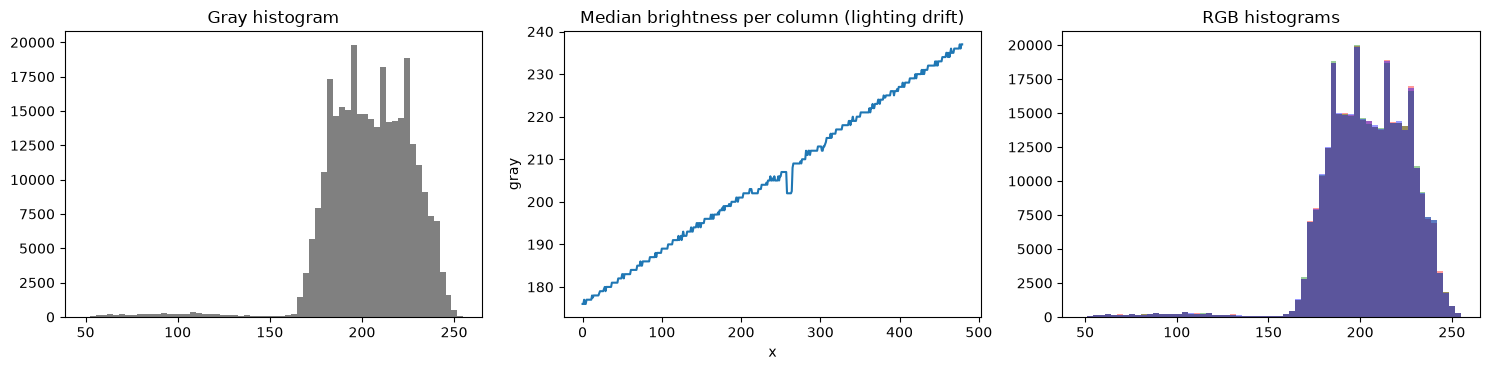

In [3]:
print("shape :", img.shape, "| dtype:", img.dtype)
print("range :", img.min(), "->", img.max())
print("mean per channel (R,G,B):", img.reshape(-1, 3).mean(0).round(1))

gray0 = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
plt.figure(figsize=(15, 3.8))
plt.subplot(1, 3, 1); plt.hist(gray0.ravel(), 64, color="gray"); plt.title("Gray histogram")
plt.subplot(1, 3, 2); plt.plot(np.median(gray0, axis=0)); plt.title("Median brightness per column (lighting drift)")
plt.xlabel("x"); plt.ylabel("gray")
plt.subplot(1, 3, 3)
for k, c in enumerate("rgb"):
    plt.hist(img[..., k].ravel(), 64, color=c, alpha=0.4)
plt.title("RGB histograms")
plt.tight_layout(); plt.show()

## 04. Image Preprocessing


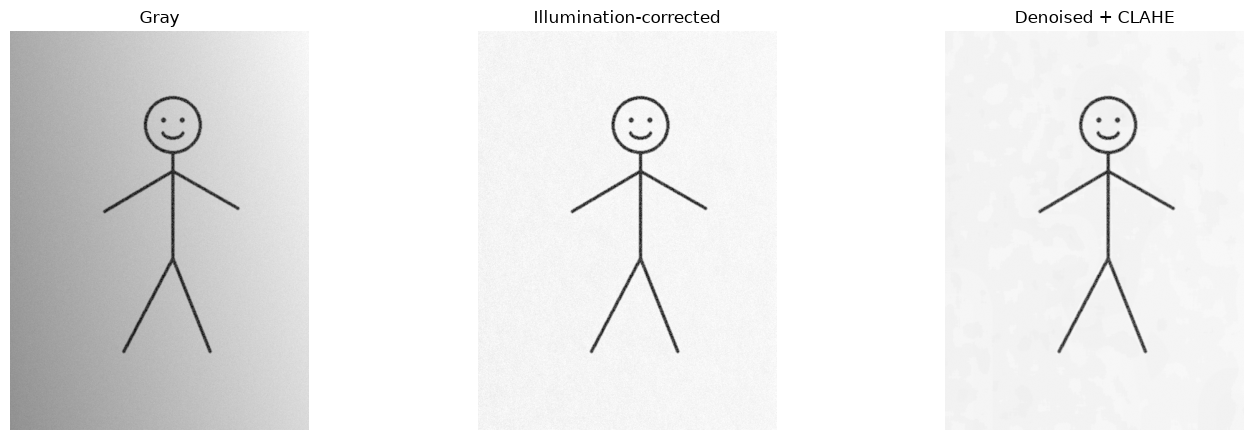

In [4]:
def preprocess(rgb):
    gray = cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY)
    bg = cv2.medianBlur(cv2.dilate(gray, np.ones((7, 7), np.uint8)), 21)   # paper estimate
    norm = cv2.divide(gray, bg, scale=255)                                  # flat lighting
    den = cv2.fastNlMeansDenoising(norm, None, 10, 7, 21)
    pre = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8)).apply(den)
    return gray, norm, pre

gray, norm, pre = preprocess(img)
show([gray, norm, pre], ["Gray", "Illumination-corrected", "Denoised + CLAHE"])

## 05. Sketch Extraction


stroke pixels: 5523


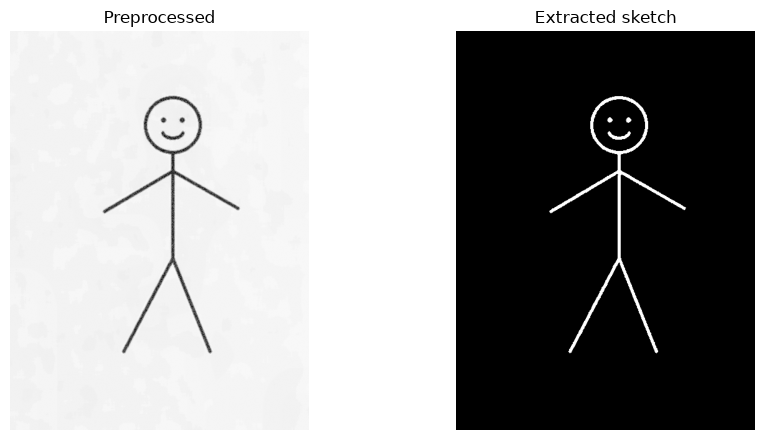

In [5]:
def extract_sketch(pre, min_area=40):
    _, otsu = cv2.threshold(pre, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
    adap = cv2.adaptiveThreshold(pre, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
                                 cv2.THRESH_BINARY_INV, 31, 10)
    sketch = cv2.bitwise_and(otsu, adap)
    sketch = cv2.morphologyEx(sketch, cv2.MORPH_CLOSE, cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3, 3)))
    n, lab, stats, _ = cv2.connectedComponentsWithStats(sketch, connectivity=8)
    keep = np.zeros_like(sketch)
    for i in range(1, n):
        if stats[i, cv2.CC_STAT_AREA] >= min_area:
            keep[lab == i] = 255
    return keep

sketch = extract_sketch(pre)
print("stroke pixels:", int((sketch > 0).sum()))
show([pre, sketch], ["Preprocessed", "Extracted sketch"], cols=2)

## 06. Contour Detection

contours found: 5


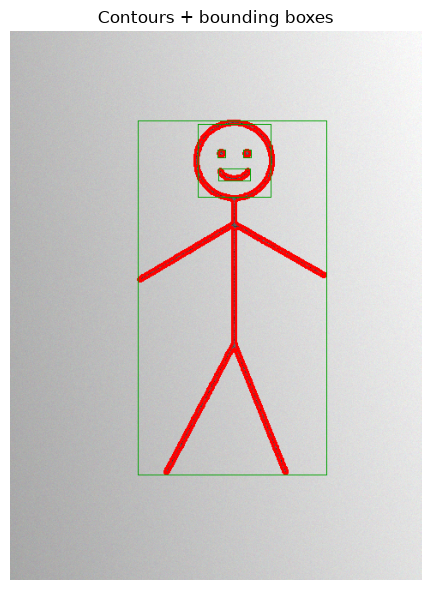

In [6]:
def detect_contours(sketch, min_area=30):
    cnts, hier = cv2.findContours(sketch, cv2.RETR_CCOMP, cv2.CHAIN_APPROX_SIMPLE)
    keep = [i for i, c in enumerate(cnts) if cv2.contourArea(c) >= min_area or cv2.arcLength(c, False) > 40]
    return [cnts[i] for i in keep], hier

cnts, hier = detect_contours(sketch)
vis = img.copy()
cv2.drawContours(vis, cnts, -1, (255, 0, 0), 2)
for c in cnts:
    x, y, w, h = cv2.boundingRect(c)
    cv2.rectangle(vis, (x, y), (x + w, y + h), (0, 160, 0), 1)
print("contours found:", len(cnts))
show([vis], ["Contours + bounding boxes"], cols=1, size=(5, 6))

## 07. Image Segmentation


character bbox: (149, 104, 220, 413)


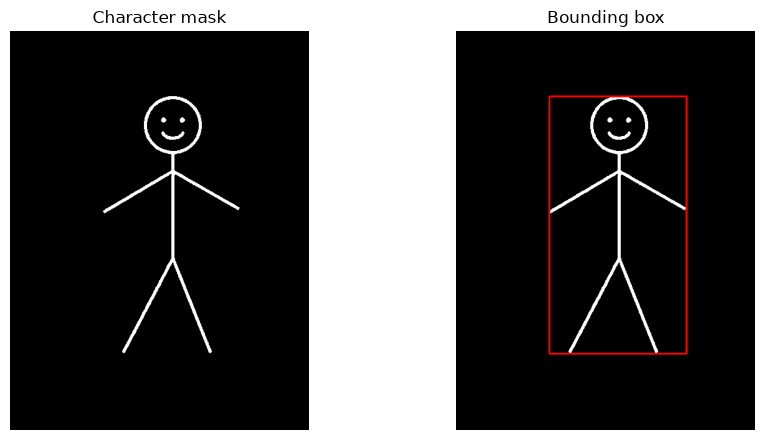

In [7]:
def segment_character(sketch):
    dil = cv2.dilate(sketch, cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (25, 25)))
    n, lab, stats, _ = cv2.connectedComponentsWithStats(dil)
    idx = 1 + int(np.argmax(stats[1:, cv2.CC_STAT_AREA]))
    region = (lab == idx).astype(np.uint8) * 255
    char = cv2.bitwise_and(sketch, region)
    bbox = cv2.boundingRect(char)                   # (x, y, w, h)
    return char, bbox

char, bbox = segment_character(sketch)
x, y, w, h = bbox
vis = cv2.cvtColor(char, cv2.COLOR_GRAY2RGB)
cv2.rectangle(vis, (x, y), (x + w, y + h), (255, 0, 0), 2)
print("character bbox:", bbox)
show([char, vis], ["Character mask", "Bounding box"], cols=2)

## 08. Part Detection


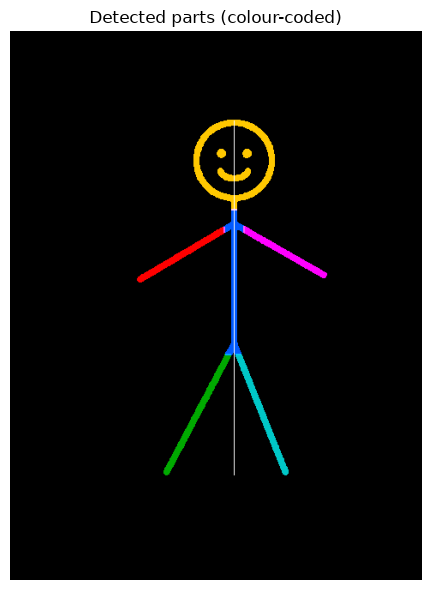

In [8]:
def detect_parts(char, bbox, band_ratio=0.05):
    x, y, w, h = bbox
    H, W = char.shape
    yy, xx = np.mgrid[0:H, 0:W]
    r = (yy - y) / float(h)                                    # relative height 0..1

    band_rows = (char[int(y + 0.30 * h): int(y + 0.55 * h)] > 0).sum(axis=0).astype(float)
    axis = int(np.argmax(np.convolve(band_rows, np.ones(5) / 5, mode="same")))   # body line x
    band = max(6, int(band_ratio * w))
    in_band = np.abs(xx - axis) <= band

    head_r  = r < 0.25
    torso_r = in_band & (r >= 0.25) & (r < 0.66)
    arm_rows = (r >= 0.25) & (r < 0.62) & ~in_band
    leg_rows = (r >= 0.62) & ~torso_r
    regions = {
        "head":  head_r,
        "torso": torso_r,
        "arm_l": arm_rows & (xx < axis),
        "arm_r": arm_rows & (xx >= axis),
        "leg_l": leg_rows & (xx < axis),
        "leg_r": leg_rows & (xx >= axis),
    }
    return regions, axis

regions, axis = detect_parts(char, bbox)
palette = {"head": (255, 200, 0), "torso": (0, 90, 255), "arm_l": (255, 0, 0),
           "arm_r": (255, 0, 255), "leg_l": (0, 170, 0), "leg_r": (0, 200, 200)}
vis = np.zeros((*char.shape, 3), np.uint8)
for n_, reg in regions.items():
    vis[(reg) & (char > 0)] = palette[n_]
vis = cv2.dilate(vis, np.ones((3, 3), np.uint8))
cv2.line(vis, (axis, bbox[1]), (axis, bbox[1] + bbox[3]), (255, 255, 255), 1)
show([vis], ["Detected parts (colour-coded)"], cols=1, size=(5, 6))

## 09. Mask Generation


head   pixels = 1801
torso  pixels = 1009
arm_l  pixels = 594
arm_r  pixels = 548
leg_l  pixels = 804
leg_r  pixels = 767


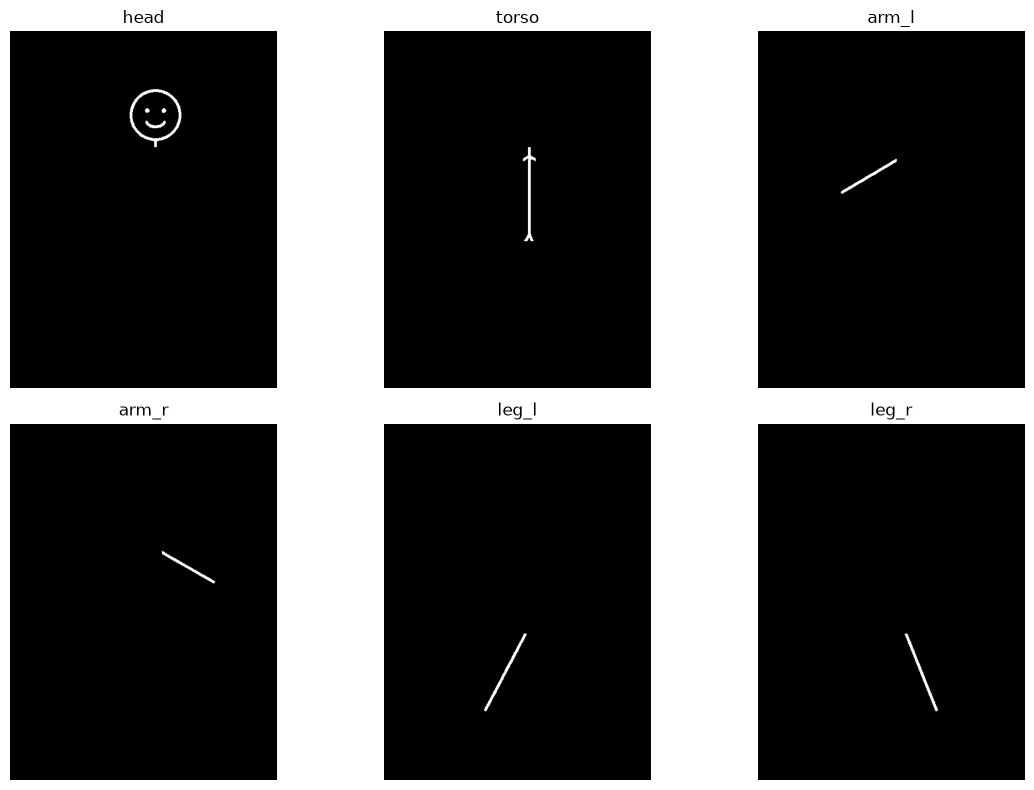

In [9]:
def generate_masks(char, regions):
    masks = {}
    for name, reg in regions.items():
        m = ((char > 0) & reg).astype(np.uint8) * 255
        masks[name] = m
    return masks

masks = generate_masks(char, regions)
for k, m in masks.items():
    print(f"{k:6s} pixels = {int((m > 0).sum())}")
show(list(masks.values()), list(masks.keys()), cols=3, size=(4, 4))

## 10. Part Extraction


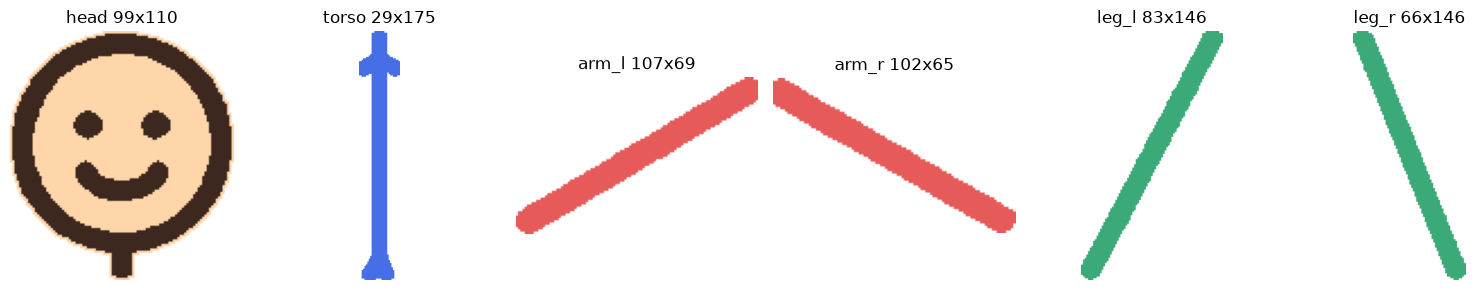

In [10]:
@dataclass
class Part:
    name: str
    rgba: np.ndarray                     # cropped RGBA image
    offset: Tuple[int, int]              # (x, y) of crop top-left in the full image
    pivot: Tuple[float, float] = (0, 0)  # rotation joint (full-image coords)
    parent: Optional[str] = None
    z: int = 0

def make_part_rgba(name, mask):
    H, W = mask.shape
    thick = cv2.dilate(mask, cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5)))
    rgba = np.zeros((H, W, 4), np.uint8)
    if name == "head":
        rgba[..., :3] = SKIN
        closed = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (15, 15)))
        cnts, _ = cv2.findContours(closed, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        fill = np.zeros_like(mask); cv2.drawContours(fill, cnts, -1, 255, -1)
        rgba[fill > 0, 3] = 255
        rgba[thick > 0] = (*DARK, 255)
    else:
        rgba[..., :3] = COLORS[name]
        rgba[thick > 0, 3] = 255
    rgba[..., 3] = cv2.GaussianBlur(rgba[..., 3], (3, 3), 0)       # smooth edges
    return rgba

def extract_parts(masks):
    out = {}
    for name, m in masks.items():
        rgba = make_part_rgba(name, m)
        ys, xs = np.where(rgba[..., 3] > 0)
        x0, x1, y0, y1 = xs.min(), xs.max() + 1, ys.min(), ys.max() + 1
        out[name] = Part(name, rgba[y0:y1, x0:x1].copy(), (int(x0), int(y0)),
                         parent=PARENT[name], z=Z_ORDER[name])
    return out

parts = extract_parts(masks)
bg_white = lambda p: np.where(p.rgba[..., 3:4] > 0, p.rgba[..., :3], 255).astype(np.uint8)
show([bg_white(p) for p in parts.values()], [f"{k} {p.rgba.shape[1]}x{p.rgba.shape[0]}" for k, p in parts.items()],
     cols=6, size=(2.6, 3))

## 11. Joint Detection


{'neck': (261, 208), 'shoulder_l': (261, 233), 'hip_l': (261, 378), 'hand_l': (151, 289), 'foot_l': (182, 514), 'shoulder_r': (261, 233), 'hip_r': (261, 378), 'hand_r': (366, 284), 'foot_r': (321, 514), 'torso_center': (261, 290)}


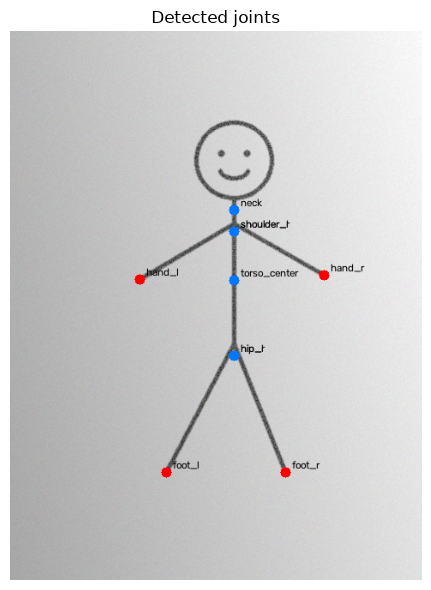

In [11]:
def _nearest(mask, ref, k=15):
    ys, xs = np.where(mask > 0)
    d = (xs - ref[0]) ** 2 + (ys - ref[1]) ** 2
    i = np.argsort(d)[:k]
    return int(np.median(xs[i])), int(np.median(ys[i]))

def _farthest(mask, ref, k=15):
    ys, xs = np.where(mask > 0)
    d = (xs - ref[0]) ** 2 + (ys - ref[1]) ** 2
    i = np.argsort(d)[-k:]
    return int(np.median(xs[i])), int(np.median(ys[i]))

def detect_joints(masks, axis, bbox):
    x, y, w, h = bbox
    ty, tx = np.where(masks["torso"] > 0)
    neck_y, torso_bot = int(ty.min()), int(ty.max())
    J = {"neck": (axis, neck_y)}
    for s in ("l", "r"):
        sh = _nearest(masks[f"arm_{s}"], (axis, neck_y + 0.08 * h))
        hp = _nearest(masks[f"leg_{s}"], (axis, torso_bot))
        J[f"shoulder_{s}"] = (axis, sh[1])            # pivot sits on the body axis
        J[f"hip_{s}"] = (axis, hp[1])
        J[f"hand_{s}"] = _farthest(masks[f"arm_{s}"], J[f"shoulder_{s}"])
        J[f"foot_{s}"] = _farthest(masks[f"leg_{s}"], J[f"hip_{s}"])
    J["torso_center"] = (axis, int(ty.mean()))
    return J

joints = detect_joints(masks, axis, bbox)
vis = img.copy()
for name, (jx, jy) in joints.items():
    col = (255, 0, 0) if name.startswith(("hand", "foot")) else (0, 120, 255)
    cv2.circle(vis, (jx, jy), 6, col, -1)
    cv2.putText(vis, name, (jx + 8, jy - 4), cv2.FONT_HERSHEY_SIMPLEX, 0.4, (0, 0, 0), 1)
print(joints)
show([vis], ["Detected joints"], cols=1, size=(5, 6))

## 12. Character Structuring


In [12]:
def build_character(parts, joints):
    pivots = {"torso": joints["torso_center"], "head": joints["neck"],
              "arm_l": joints["shoulder_l"], "arm_r": joints["shoulder_r"],
              "leg_l": joints["hip_l"], "leg_r": joints["hip_r"]}
    for name, p in parts.items():
        p.pivot = tuple(map(float, pivots[name]))
    return parts

def print_tree(parts, root="torso", depth=0):
    p = parts[root]
    print("  " * depth + f"- {root}  pivot={tuple(int(v) for v in p.pivot)}  z={p.z}")
    for n, q in parts.items():
        if q.parent == root:
            print_tree(parts, n, depth + 1)

character = build_character(parts, joints)
print_tree(character)

- torso  pivot=(261, 290)  z=1
  - head  pivot=(261, 208)  z=3
  - arm_l  pivot=(261, 233)  z=2
  - arm_r  pivot=(261, 233)  z=2
  - leg_l  pivot=(261, 378)  z=0
  - leg_r  pivot=(261, 378)  z=0


## 13. Output Generation


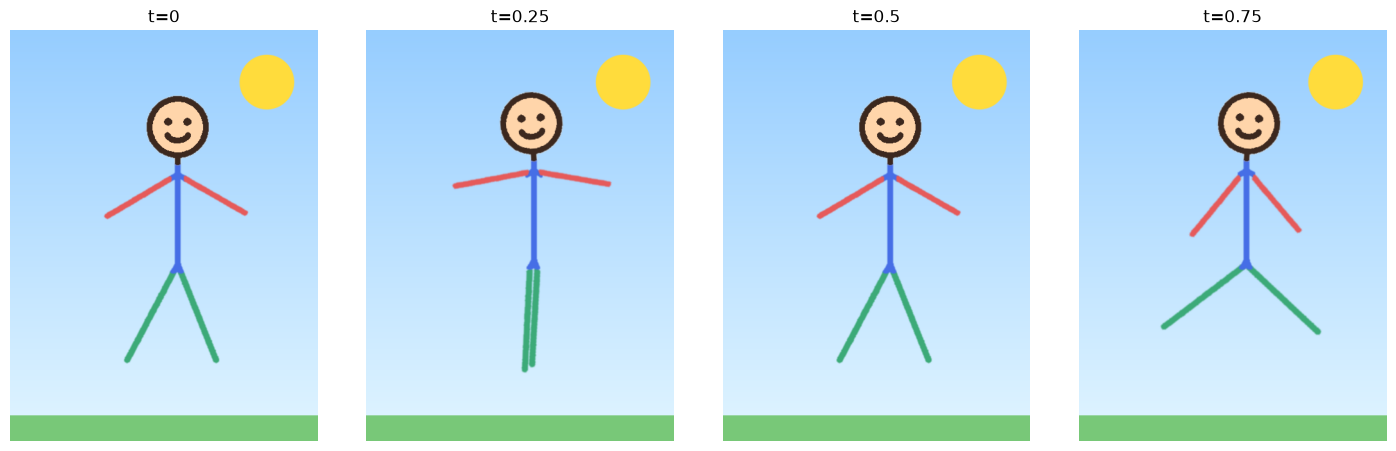

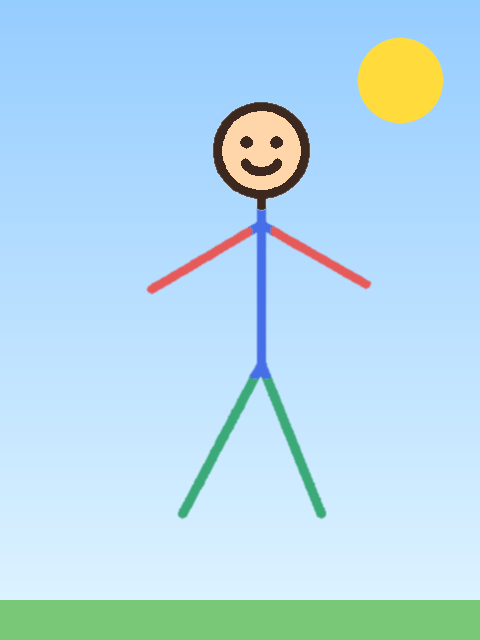

saved: outputs\walk.gif


In [13]:
def pose(animation, t):
    s = np.sin(2 * np.pi * t)
    if animation == "walk":
        return {"leg_l": 25 * s, "leg_r": -25 * s, "arm_l": -20 * s, "arm_r": 20 * s,
                "head": 4 * s}, -abs(s) * 6
    if animation == "wave":
        return {"arm_r": 70 + 20 * s, "head": 6 * s}, 0
    if animation == "dance":
        return {"arm_l": -(60 + 25 * s), "arm_r": 60 - 25 * s, "leg_l": 12 * s, "leg_r": 12 * s,
                "head": 10 * s}, -abs(np.sin(4 * np.pi * t)) * 8
    return {}, 0

def make_background(shape):
    H, W = shape[:2]
    top, bot = np.array([150, 205, 255.]), np.array([225, 245, 255.])
    g = np.linspace(0, 1, H)[:, None, None]
    bg = (top * (1 - g) + bot * g) * np.ones((1, W, 1))
    bg = bg.astype(np.uint8)
    cv2.circle(bg, (W - 80, 80), 42, (255, 220, 60), -1, cv2.LINE_AA)           # sun
    cv2.rectangle(bg, (0, H - 40), (W, H), (120, 200, 120), -1)                  # ground
    return bg

def _rot(pivot, angle):
    M = cv2.getRotationMatrix2D((float(pivot[0]), float(pivot[1])), angle, 1.0)
    return np.vstack([M, [0, 0, 1]])

def render_frame(parts, shape, angles, bob=0.0, bg=None):
    H, W = shape[:2]
    canvas = (bg if bg is not None else make_background(shape)).astype(np.float32)
    world = {}
    def get_world(name):                                   # accumulate parent transforms
        if name not in world:
            local = _rot(parts[name].pivot, angles.get(name, 0.0))
            par = parts[name].parent
            world[name] = (get_world(par) @ local) if par else local
        return world[name]
    for p in sorted(parts.values(), key=lambda q: q.z):
        layer = np.zeros((H, W, 4), np.uint8)
        x0, y0 = p.offset; h, w = p.rgba.shape[:2]
        layer[y0:y0 + h, x0:x0 + w] = p.rgba
        M = get_world(p.name)[:2].copy(); M[1, 2] += bob
        layer = cv2.warpAffine(layer, M, (W, H), flags=cv2.INTER_LINEAR, borderValue=(0, 0, 0, 0))
        a = layer[..., 3:4] / 255.0
        canvas = canvas * (1 - a) + layer[..., :3] * a
    return canvas.astype(np.uint8)

def generate_animation(parts, shape, animation="walk", n_frames=24):
    bg = make_background(shape)
    frames = []
    for i in range(n_frames):
        angles, bob = pose(animation, i / n_frames)
        frames.append(render_frame(parts, shape, angles, bob, bg))
    return frames

def save_gif(frames, path, fps=15):
    pil = [PILImage.fromarray(f) for f in frames]
    pil[0].save(path, save_all=True, append_images=pil[1:], duration=int(1000 / fps), loop=0)
    return path

frames = generate_animation(character, img.shape, "walk", 24)
gif_path = save_gif(frames, os.path.join(OUT_DIR, "walk.gif"))
show([frames[i] for i in (0, 6, 12, 18)], ["t=0", "t=0.25", "t=0.5", "t=0.75"], cols=4, size=(3.6, 4.5))
if IPyImage: display(IPyImage(filename=gif_path))
print("saved:", gif_path)

## 14. Pipeline Testing


config                                 parts joints moving  time(s)
{'seed': 1}                            True  True   True   3.34
{'seed': 2, 'noise': 8}                True  True   True   3.73
{'seed': 3, 'rotate': 3}               True  True   True   2.56
{'seed': 4, 'noise': 6, 'rotate': -3}  True  True   True   3.59
{'seed': 5}                            True  True   True   4.83

ALL TESTS PASSED ✅


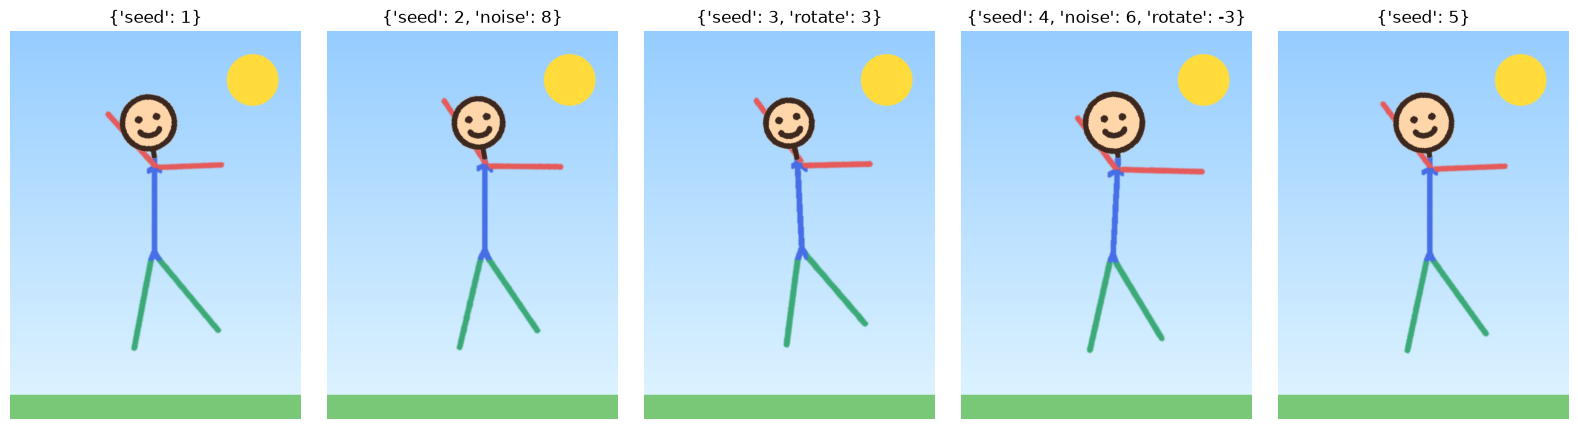

In [14]:
def run_pipeline(rgb, animation="walk", n_frames=24):
    gray, norm, pre = preprocess(rgb)
    sketch = extract_sketch(pre)
    char, bbox = segment_character(sketch)
    regions, axis = detect_parts(char, bbox)
    masks = generate_masks(char, regions)
    joints = detect_joints(masks, axis, bbox)
    parts = build_character(extract_parts(masks), joints)
    frames = generate_animation(parts, rgb.shape, animation, n_frames)
    return {"sketch": sketch, "char": char, "bbox": bbox, "masks": masks,
            "joints": joints, "parts": parts, "frames": frames}

tests = [dict(seed=1), dict(seed=2, noise=8), dict(seed=3, rotate=3), dict(seed=4, noise=6, rotate=-3), dict(seed=5)]
rows, thumbs = [], []
for kw in tests:
    im = generate_synthetic_drawing(**kw)
    t0 = time.time()
    res = run_pipeline(im, "dance", 12)
    dt = time.time() - t0

    ok_parts = all((m > 0).sum() > 50 for m in res["masks"].values())
    ok_joints = len(res["joints"]) == 10
    moved = np.abs(res["frames"][0].astype(int) - res["frames"][3].astype(int)).mean() > 0.2
    assert ok_parts and ok_joints and moved, f"pipeline failed on {kw}"
    rows.append((kw, ok_parts, ok_joints, moved, round(dt, 2)))
    thumbs.append(res["frames"][3])

print(f"{'config':38s} parts joints moving  time(s)")
for kw, a, b, c, dt in rows:
    print(f"{str(kw):38s} {a!s:5s} {b!s:6s} {c!s:6s} {dt}")
print("\nALL TESTS PASSED ✅")
show(thumbs, [str(k) for k in tests], cols=5, size=(3.2, 4.2))

## 15. Pipeline Export


exported -> hand_drawn_pipeline.py (10.5 KB)
exported pipeline OK -> outputs\exported_wave.gif


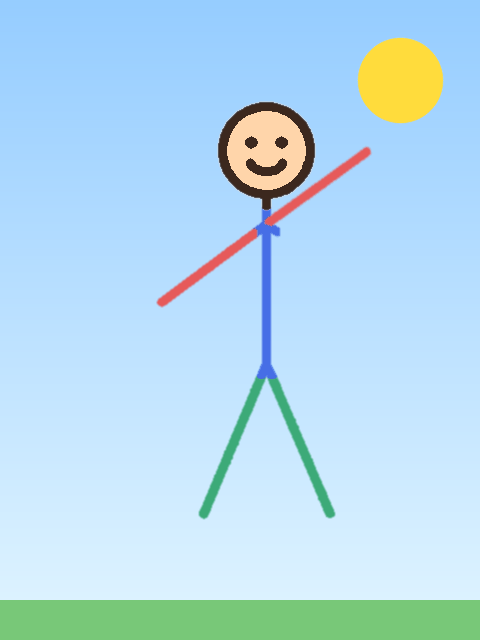

In [15]:
EXPORT_FUNCS = [make_part_rgba, preprocess, extract_sketch, detect_contours, segment_character,
                detect_parts, generate_masks, extract_parts, _nearest, _farthest, detect_joints,
                build_character, pose, make_background, _rot, render_frame, generate_animation,
                save_gif, run_pipeline]

header = (
    '"""Hand-drawn sketch -> animated cartoon (exported from Hand_Drawn_Animation.ipynb)"""\n'
    "import numpy as np, cv2\n"
    "from dataclasses import dataclass\n"
    "from typing import Optional, Tuple\n"
    "from PIL import Image as PILImage\n\n"
    f"SKIN = {SKIN!r}\nDARK = {DARK!r}\nCOLORS = {COLORS!r}\n"
    f"PARENT = {PARENT!r}\nZ_ORDER = {Z_ORDER!r}\n\n"
)
PART_SRC = """@dataclass
class Part:
    name: str
    rgba: np.ndarray
    offset: Tuple[int, int]
    pivot: Tuple[float, float] = (0, 0)
    parent: Optional[str] = None
    z: int = 0
"""
def _src(f):
    try:
        return inspect.getsource(f)
    except (OSError, TypeError):
        # fallback: look the function up in the notebook's cell history
        ip = get_ipython()
        for cell in ip.user_ns.get("In", [])[::-1]:
            if f"def {f.__name__}(" in cell:
                start = cell.index(f"def {f.__name__}(")
                nxt = cell.find("\ndef ", start + 1)
                return cell[start: nxt if nxt != -1 else len(cell)].rstrip() + "\n"
        raise

body = PART_SRC + "\n\n" + "\n\n".join(_src(f) for f in EXPORT_FUNCS)

live = """

def live_demo(camera=0):
    # c = capture drawing | w = wave | d = dance | a = walk | q = quit
    cap = cv2.VideoCapture(camera)
    parts, shape, anim, t, bg = None, None, "walk", 0.0, None
    while True:
        ok, frame = cap.read()
        if not ok:
            break
        key = cv2.waitKey(30) & 0xFF
        if key == ord("c"):
            rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
            try:
                res = run_pipeline(rgb, n_frames=1)
                parts, shape = res["parts"], rgb.shape
                bg = make_background(shape)
            except Exception as e:
                print("capture failed:", e)
        elif key in (ord("w"), ord("d"), ord("a")):
            anim = {ord("w"): "wave", ord("d"): "dance", ord("a"): "walk"}[key]
        elif key == ord("q"):
            break
        if parts is not None:
            angles, bob = pose(anim, t % 1.0)
            out = render_frame(parts, shape, angles, bob, bg)
            cv2.imshow("Magic Sketchbook", cv2.cvtColor(out, cv2.COLOR_RGB2BGR))
            t += 0.04
        cv2.imshow("Camera", frame)
    cap.release(); cv2.destroyAllWindows()


if __name__ == "__main__":
    live_demo()
"""
export_path = "hand_drawn_pipeline.py"
with open(export_path, "w") as f:
    f.write(header + body + live)
print("exported ->", export_path, f"({os.path.getsize(export_path)/1024:.1f} KB)")

# ---- verify the exported module works on its own ----
import importlib.util
spec = importlib.util.spec_from_file_location("hand_drawn_pipeline", export_path)
mod = importlib.util.module_from_spec(spec); spec.loader.exec_module(mod)
res = mod.run_pipeline(generate_synthetic_drawing(seed=7), "wave", 12)
mod.save_gif(res["frames"], os.path.join(OUT_DIR, "exported_wave.gif"))
print("exported pipeline OK ->", os.path.join(OUT_DIR, "exported_wave.gif"))
if IPyImage: display(IPyImage(filename=os.path.join(OUT_DIR, "exported_wave.gif")))

###  ملخص
Image → Preprocess → Sketch → Contours → Character segmentation → Part detection → Masks → RGBA parts → Joints → Rig → Animation GIF.

